# 02 · Price dynamics

How does the cheapest fare for a trip move as departure gets closer? This is
the behavior any buy-or-wait rule has to exploit.

**Key takeaways**
1. I track the **cheapest option per route and flight date**, not one
   specific itinerary. Individual itineraries come and go too often to
   follow (median: seen on only 7 days).
2. Fares are **flat from about 45 to 14 days out, then climb fast**, in
   steps at about 21, 14 and 7 days. One day before departure, the typical
   fare is about 60% above the trip's usual level.
3. Prices **jump rather than drift**. On 60% of days the cheapest fare
   doesn't change at all, and when it does, the median move is about $21
   (14%).
4. In hindsight, waiting often pays: 60 days out, a cheaper fare showed up
   later 88% of the time. The hard part is knowing *when*, which is the
   whole project.
5. Spirit and Frontier are most often the cheapest, and Southwest isn't in
   the data at all.

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

from flight_pricing.data import connect
from flight_pricing.plotting import SERIES, use_style

use_style()
con = connect()

def q(sql):
    return con.sql(sql).df()

## The core table

`scripts/build_cheapest.py` collapses the 82M rows into one row per
**route × flight date × search date**: the cheapest fare I could have
bought that day, plus which itinerary it was. That matches how I search:
cheapest way from A to B on my date, basic economy included.

I call one route on one flight date a **trip** (for example, ATL → BOS on
July 1).

In [2]:
q("""
SELECT count(*) AS n_rows,
       count(DISTINCT (origin, dest, flightDate)) AS trips,
       median(n_options) AS median_options_per_search,
       avg(isNonStop::INT) AS cheapest_is_nonstop,
       avg(isBasicEconomy::INT) AS cheapest_is_basic_econ
FROM cheapest
""").round(2)

,n_rows,trips,median_options_per_search,cheapest_is_nonstop,cheapest_is_basic_econ
0,1987439,50759,38.0,0.53,0.21


On a typical day there are about 38 options for a trip, and I keep the
cheapest. About half the time the cheapest is nonstop, and about a fifth of
the time it's basic economy.

For the rest of this notebook I only use trips whose **whole 60-day window**
falls inside the collection period (flights from June 15 to October 6), so
every trip can be followed from 60 days out to departure.

In [3]:
con.execute("""
CREATE VIEW full_trips AS
SELECT *, fare / median(fare) OVER (PARTITION BY origin, dest, flightDate) AS rel_fare
FROM cheapest
WHERE flightDate BETWEEN DATE '2022-06-15' AND DATE '2022-10-06'
""")

q("""
SELECT count(*) AS trips, avg(n) AS avg_days_observed, median(n) AS median_days_observed
FROM (SELECT origin, dest, flightDate, count(*) AS n FROM full_trips GROUP BY ALL)
""").round(1)

,trips,avg_days_observed,median_days_observed
0,26677,52.5,53.0


That's 26,677 trips, each seen on about 53 of its 60 possible days. The
missing days are mostly the collection gaps from notebook 01: 93% of
consecutive observations are exactly one day apart.

## Why not follow one itinerary?

In [4]:
q("""
SELECT median(n) AS median_days_seen,
       avg((last_days_ahead > 3)::INT) AS share_gone_before_last_3_days
FROM (SELECT legId, flightDate, count(DISTINCT searchDate) AS n,
             min(datediff('day', searchDate, flightDate)) AS last_days_ahead
      FROM itin WHERE flightDate BETWEEN DATE '2022-06-15' AND DATE '2022-10-06'
      GROUP BY ALL)
""").round(2)

,median_days_seen,share_gone_before_last_3_days
0,7.0,0.58


A specific itinerary is seen on only 7 days (median), and 58% disappear
more than 3 days before departure. *My guess:* some sell out, but many
probably just drop out of Expedia's search results or get rescheduled.
Either way, following one itinerary would leave most trips with broken
price histories. The cheapest-per-trip view doesn't have that problem, and
it's closer to how I shop anyway.

The trade-off: the cheapest option switches to a different itinerary on 30%
of days, so some "price changes" are really switches.

## How fares move toward departure

To compare cheap and expensive routes on one chart, I divide each fare by
that trip's median fare. **1.0 means "this trip's usual price"**, and 1.5
means 50% above it.

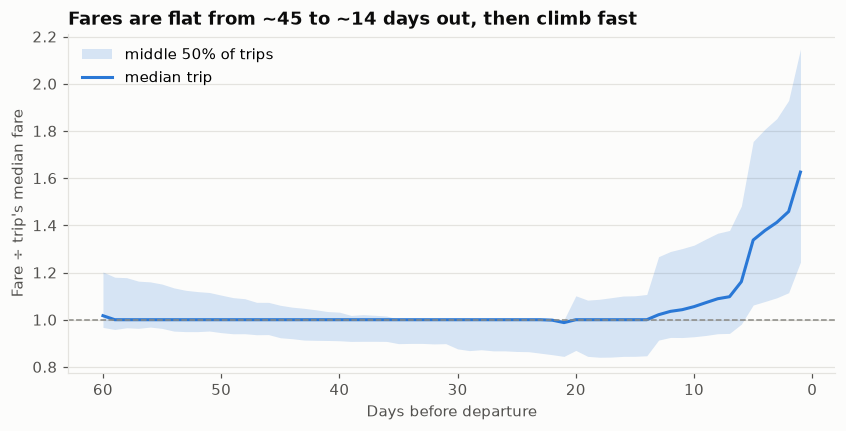

In [5]:
curve = q("""
SELECT days_ahead,
       quantile_cont(rel_fare, 0.25) AS p25,
       median(rel_fare) AS med,
       quantile_cont(rel_fare, 0.75) AS p75
FROM full_trips GROUP BY 1 ORDER BY 1
""")

fig, ax = plt.subplots()
ax.fill_between(curve.days_ahead, curve.p25, curve.p75, color=SERIES[0], alpha=0.18,
                linewidth=0, label="middle 50% of trips")
ax.plot(curve.days_ahead, curve.med, color=SERIES[0], label="median trip")
ax.axhline(1, color="#8a8984", linewidth=1, linestyle="--")
ax.set_title("Fares are flat from ~45 to ~14 days out, then climb fast")
ax.set_xlabel("Days before departure")
ax.set_ylabel("Fare ÷ trip's median fare")
ax.invert_xaxis()
ax.legend(loc="upper left")
plt.show()

Read this chart left to right, the way time moves. From 60 days out the
typical fare eases down to its usual level and stays flat until about two
weeks out. Then it rises steeply: about 1.1× at 7 days, 1.4× at 3 days and
1.6× the day before departure. The cheapest stretch for the lower quarter of
trips is around **2–3 weeks out**.

The rise isn't smooth. It comes in **steps at about 21, 14 and 7 days**.
*My guess:* these are airlines' advance-purchase deadlines, where cheaper
fare classes can only be bought until a set number of days before departure.
If so, "buy before the next deadline" is a real signal, and days-to-departure
will be one of the most important inputs to the model.

This already gives me a strong simple rule to beat: "buy about 3 weeks
out." Any model has to do better than that to be worth it.

## Do prices jump or drift?

In [6]:
q("""
WITH d AS (
    SELECT fare, legId, days_ahead,
           lag(fare) OVER w AS prev_fare,
           lag(legId) OVER w AS prev_leg,
           lag(days_ahead) OVER w AS prev_days
    FROM full_trips
    WINDOW w AS (PARTITION BY origin, dest, flightDate ORDER BY days_ahead DESC)
)
SELECT avg((fare = prev_fare)::INT) AS unchanged,
       avg((fare < prev_fare)::INT) AS went_down,
       avg((fare > prev_fare)::INT) AS went_up,
       median(abs(fare - prev_fare)) FILTER (WHERE fare <> prev_fare) AS median_change_usd,
       median(abs(fare / prev_fare - 1)) FILTER (WHERE fare <> prev_fare) AS median_change_pct,
       avg((legId <> prev_leg)::INT) AS cheapest_switched_itinerary
FROM d WHERE prev_days = days_ahead + 1
""").round(3)

,unchanged,went_down,went_up,median_change_usd,median_change_pct,cheapest_switched_itinerary
0,0.599,0.178,0.223,20.98,0.138,0.301


Day to day, the cheapest fare **stays exactly the same 60% of the time**.
When it moves, it moves by a lot: a median of about $21, or 14%. That's
what I expected from the spikes in notebook 01. Airlines sell seats in
fixed fare classes, so prices hop between levels instead of drifting a few
cents at a time.

This matters for the MATLAB step: a model where the price **moves between
discrete levels** (a Markov chain) is a natural fit for this data.

## In hindsight, would waiting have paid off?

For every trip and day, I check whether a **cheaper fare appeared later**
before departure. This uses future prices, so it's **not a strategy**. No
one knows the future. It's an upper bound on what waiting could ever save.

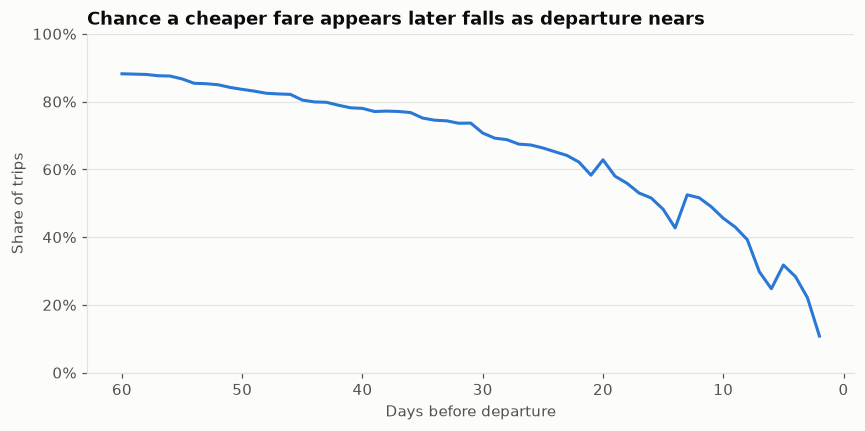

,days_ahead,p_cheaper_later,avg_pct_drop
1,3,0.221,0.141
5,7,0.298,0.165
12,14,0.427,0.194
19,21,0.583,0.241
28,30,0.707,0.267
43,45,0.804,0.300
58,60,0.882,0.346


In [7]:
hindsight = q("""
WITH f AS (
    SELECT *, min(fare) OVER (PARTITION BY origin, dest, flightDate ORDER BY days_ahead
                              ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING) AS future_min
    FROM full_trips
)
SELECT days_ahead,
       avg((future_min < fare)::INT) AS p_cheaper_later,
       avg(1 - future_min / fare) FILTER (WHERE future_min < fare) AS avg_pct_drop
FROM f WHERE days_ahead >= 2 GROUP BY 1 ORDER BY 1
""")

fig, ax = plt.subplots()
ax.plot(hindsight.days_ahead, hindsight.p_cheaper_later, color=SERIES[0])
ax.set_title("Chance a cheaper fare appears later falls as departure nears")
ax.set_xlabel("Days before departure")
ax.set_ylabel("Share of trips")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1))
ax.set_ylim(0, 1)
ax.invert_xaxis()
plt.show()

hindsight.query("days_ahead in [60, 45, 30, 21, 14, 7, 3]").round(3)

60 days out, a cheaper fare showed up later for 88% of trips, typically
about 35% cheaper. At 3 weeks out it's 58%, and at 1 week it's 30%. So there
usually *is* money to be saved by waiting, especially early on.

The small bumps right after 21, 14 and 7 days fit the deadline idea: once a
cheap fare class closes, the price jumps up, so the chance of finding
something cheaper later briefly rises again.

The catch is that the cheapest moment is only obvious afterward. Wait too
long and you hit the late price spike. That tension between waiting for a
drop and risking the spike is exactly the buy-or-wait problem.

## Who sells the cheapest fares?

In [8]:
q("""
SELECT split_part(airlines, '||', 1) AS airline,
       count(*) AS times_cheapest,
       count(*) / sum(count(*)) OVER () AS share
FROM cheapest GROUP BY 1 ORDER BY 2 DESC LIMIT 7
""").round(3)

,airline,times_cheapest,share
0,Spirit Airlines,650273,0.327
1,United,344795,0.173
2,Frontier Airlines,280657,0.141
3,Delta,255245,0.128
4,JetBlue Airways,246117,0.124
5,American Airlines,179012,0.090
6,Alaska Airlines,26829,0.013


Ultra-low-cost carriers lead: **Spirit** is the cheapest option a third of
the time, and **Frontier** is third. Two things to keep in mind:

- **Bag fees aren't in the fare.** Spirit and Frontier charge extra for
  carry-ons and checked bags, so their "cheapest" fare can cost more in
  practice. My analysis compares listed fares.
- **Southwest doesn't appear at all.** *My guess:* Southwest doesn't sell
  through Expedia, so a major low-fare airline is missing from the data.

Both go on the limitations list.

## Next: notebook 03

Turn this into a precise decision problem: what "buy" and "wait" mean each
day, what a strategy is, how it's scored in $ and %, and the simple rules
every model must beat (buy now, buy at a fixed number of days out, and the
hindsight best as an upper bound).